# NYU CSCI-GA 3033-091 — Homework 2, Problem 4
## Approximate Nearest Neighbors (25 points)

**Intro to LLM Based Generative AI Systems · Fall 2026**
**Due:** October 15, 2026
**Instructors:** Parijat Dube and Chen Wang
**TAs:** Raj Appana and Satyapragnya Kar

Implement and analyze a simplified, HNSW-inspired hierarchical nearest-neighbor graph.
This classroom construction connects nearest neighbors using all-pairs distances in
each layer; it is **not production HNSW** (no incremental insertion, neighbor
pruning, or `ef` candidate search). Its greedy search can stop at local minima.

**Required test parameters:** 100 vectors, dimension 2, `m_neighbors = 2`,
query `[0.5, 0.5]`. Use Euclidean distance throughout.

**Required libraries:** numpy, networkx, matplotlib (CPU only).
Submit documented code, graph/path visualizations, and your own measured analysis.
Required tasks: construction **10**, search **8**, evaluation **7** points.
Optional bonuses: M comparison **+3**, real embeddings **+2**.

**Name / NetID:** _Mayank Garg mg8948___________________


### Google Colab setup — one notebook, CPU only
Open [Google Colab](https://colab.research.google.com/), choose **File → Upload notebook**, and upload this `.ipynb` alone. Leave the hardware accelerator set to **None**; no GPU, repository clone, `.py` files, or requirements upload is needed.

Run the setup cell before imports. It installs the three required packages only if needed, without an unconditional upgrade. If packages were installed, restart the session and run from the top. Complete the TODOs before running the corresponding task cells. The optional embedding bonus requires a separate, opt-in gensim installation/download.

Save your work with **File → Download → Download .ipynb** (including your generated plots and analysis). Colab runtime files are temporary; download any separate figures before the runtime is deleted. The same notebook also works in a local Jupyter environment.

In [1]:
# Self-contained CPU setup; existing compatible packages are left unchanged.
import importlib.metadata as metadata
import subprocess
import sys
from packaging.requirements import Requirement

P4_PACKAGES = ("numpy>=1.26,<3", "networkx>=3,<4", "matplotlib>=3.8,<4")
missing = []
for spec in P4_PACKAGES:
    requirement = Requirement(spec)
    try:
        installed = metadata.version(requirement.name)
    except metadata.PackageNotFoundError:
        installed = None
    if installed is None or not requirement.specifier.contains(installed):
        missing.append(spec)
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--upgrade-strategy",
                    "only-if-needed", *missing], check=True)
    raise RuntimeError("Packages installed. Restart the Colab session/Jupyter kernel, then run from the top.")
print({Requirement(spec).name: metadata.version(Requirement(spec).name) for spec in P4_PACKAGES})

# Optional real-embedding bonus only (not required for the base tasks):
# %pip install gensim

{'numpy': '2.1.3', 'networkx': '3.7', 'matplotlib': '3.10.0'}


### (10 points) Task (a):

Implement `construct_HNSW(vectors, m_neighbors)`:

- Input: finite NumPy array `(n_vectors, dimension)` and positive integer M.
- Assign maximum levels using `floor(-log(U) / log(max(M, 2)))` with U uniform in (0, 1).
- Return a **base-first** list of undirected `networkx.Graph` layers, layer 0 containing
  all vectors. Node IDs are original row indices; each node has `pos=vectors[i]`.
- Nodes assigned maximum level L appear in every layer 0 through L.
- Within each layer, connect each node to its M nearest other nodes (or all others
  if fewer exist). Undirected incoming links mean **M is not a maximum degree**.
- Use the seeded setup below for reproducibility and visualize the layer structure.

This all-pairs classroom construction is not a scalable production index.


In [2]:
# Import required libraries
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import time

# Set random seed for reproducibility
np.random.seed(42)

# Define number of vectors, dimension, m-nearest-neighbors and generate a random dataset
# (specs mentioned above and in the PDF)
n_vectors   = 100
dimension   = 2
m_neighbors = 2

vectors = np.random.rand(n_vectors, dimension)
print(f"Dataset shape: {vectors.shape}")


Dataset shape: (100, 2)


#### Query Vector

In [3]:
# Define the query vector
query     = np.array([0.5, 0.5])
query_vec = query   # alias for use in Task (c)
print(f"Query vector: {query}")


Query vector: [0.5 0.5]


#### HNSW Construction

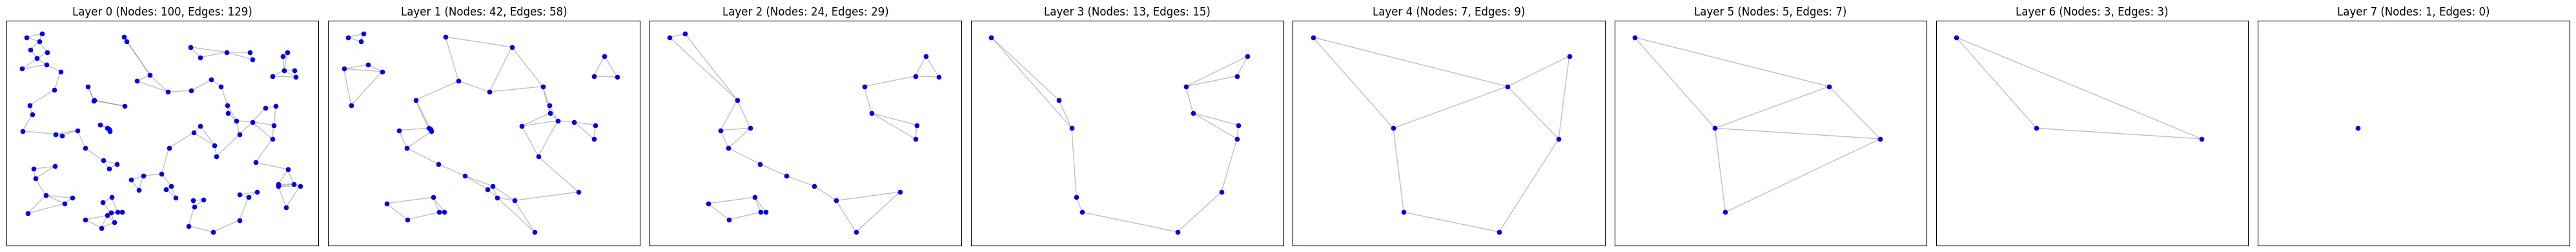

In [4]:
def construct_HNSW(vectors, m_neighbors):
    """Return base-first nested nx.Graph layers with original IDs and node pos vectors."""
    n = len(vectors)
    levels = []
    for i in range(n):
        U = np.random.rand()
        L_i = int(np.floor(-np.log(U) / np.log(max(m_neighbors, 2))))
        levels.append(L_i)

    max_level = max(levels)
    graph_layers = []

    for l in range(max_level + 1):
        G = nx.Graph()
        layer_nodes = [i for i in range(n) if levels[i] >= l]
        for node in layer_nodes:
            G.add_node(node, pos=vectors[node])

        num_nodes = len(layer_nodes)
        for i, u in enumerate(layer_nodes):

            distances = []
            for v in layer_nodes:
                if u != v:
                    dist = np.linalg.norm(vectors[u] - vectors[v])
                    distances.append((dist, v))

            distances.sort(key=lambda x: x[0])

            k = min(m_neighbors, len(distances))
            for rank in range(k):
                _, v = distances[rank]
                G.add_edge(u, v)

        graph_layers.append(G)

    return graph_layers

GraphArray = construct_HNSW(vectors, m_neighbors)

# Visualize the layer structure
fig, axes = plt.subplots(1, len(GraphArray), figsize=(5 * len(GraphArray), 4), squeeze=False)
for l, G in enumerate(GraphArray):
    ax = axes[0, l]
    pos = nx.get_node_attributes(G, 'pos')
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=20, node_color='blue')
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.5, edge_color='gray')
    ax.set_title(f"Layer {l} (Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()})")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

### (8 points) Task (b):

Implement `search_HNSW(graph_layers, query)` using top-down greedy descent:

- Enter at the first node in the highest nonempty layer.
- At each layer, repeatedly move to the neighbor with the smallest distance to the
  query, but only if it strictly improves the current distance; then descend.
- Return **`(nearest_index, per_layer_paths)`**. `nearest_index` is the original vector
  row index, not a vector or graph. `per_layer_paths` is a top-to-bottom list of
  `(layer_index, [visited_node_ids])` pairs, including the entry and final node of
  each layer. Include the base-layer path even if it contains only one node.
- The graphs must follow Task (a)'s nested, base-first representation.

The greedy result is approximate: stopping at a local minimum need not return the
true nearest neighbor. Do not silently replace it with brute-force search.


In [5]:
import pandas as pd

In [6]:
def search_HNSW(graph_layers, query):
    """Return (nearest_index, per_layer_paths); paths are (layer, [node IDs]) pairs."""
    # TODO: implement the specified top-down greedy walk.
    q = np.asarray(query)
    def distance(node, graph):
      return np.linalg.norm(np.asarray(graph.nodes[node]["pos"]) - q)
    curr = next(iter(graph_layers[-1].nodes))
    per_layer_paths = []
    # bestDist = distance(curr, graph_layers)

    for layer_idx in range(len(graph_layers) -1, -1, -1):
      graph = graph_layers[layer_idx]
      path = [curr]
      while True:
        best_node = curr
        best_dist = distance(curr, graph)

        for neighbor in graph.neighbors(curr):
          d = distance(neighbor, graph)

          if d< best_dist:
            best_dist = d
            best_node = neighbor
        if best_node == curr:
          break
        curr = best_node
        path.append(curr)
      per_layer_paths.append((layer_idx, path))

    return curr, per_layer_paths




nearest_index, per_layer_paths = search_HNSW(GraphArray, query)
# TODO: report the approximate index, vector, distance, and full path table.
nearest_vector = np.asarray(GraphArray[0].nodes[nearest_index]["pos"])
nearest_distance = np.linalg.norm(nearest_vector - np.asarray(query))

print("Approximate Index:", nearest_index)
print("Approximate Vector:", nearest_vector)
print("Distance:", nearest_distance)

# Full path table
rows = []

for layer, path in per_layer_paths:
    graph = GraphArray[layer]

    for step, node in enumerate(path):
        vector = np.asarray(graph.nodes[node]["pos"])

        rows.append({
            "Layer": layer,
            "Step": step,
            "Node": node,
            "Vector": vector.tolist(),
            "Distance": np.linalg.norm(vector - np.asarray(query))
        })

path_table = pd.DataFrame(rows)

display(path_table)

Approximate Index: 51
Approximate Vector: [0.31435598 0.50857069]
Distance: 0.18584175663497668


,Layer,Step,Node,Vector,Distance
0,7,0,8,"[0.3042422429595377, 0.5247564316322378]",0.197317
1,6,0,8,"[0.3042422429595377, 0.5247564316322378]",0.197317
2,5,0,8,"[0.3042422429595377, 0.5247564316322378]",0.197317
3,4,0,8,"[0.3042422429595377, 0.5247564316322378]",0.197317
4,3,0,8,"[0.3042422429595377, 0.5247564316322378]",0.197317
5,2,0,8,"[0.3042422429595377, 0.5247564316322378]",0.197317
6,1,0,8,"[0.3042422429595377, 0.5247564316322378]",0.197317
7,1,1,51,"[0.3143559810763267, 0.5085706911647028]",0.185842
8,0,0,51,"[0.3143559810763267, 0.5085706911647028]",0.185842


### (7 points) Task (c):

Evaluate your implementation on the required 100 vectors in 2D:

- Compare the fixed query's approximate index and distance against exact search.
- Measure average search time for both methods using **1,000 repetitions** of the
  fixed query, excluding construction and plotting; report the observed times.
- Visualize graph layers and one search path, including **layer 0**, query, entry,
  approximate result, and exact result. Label visited nodes with original row IDs;
  use marker shapes/line styles and a legend, not color alone. Include a text table
  of the full top-to-bottom paths so omitted intermediate panels are explicit.
- Calculate **recall@1** (exact nearest-index agreement) on **200 random queries**
  using evaluation seed 0. Distinguish this rate from agreement on one fixed query.

Use blue/orange plus neutral colors for readable NetworkX/Matplotlib plots.
Do not assert that approximate search is always correct or faster; at this scale,
vectorized brute force may be faster. No larger benchmark is required.


### Brute Force

In [7]:
def nearest_neighbor(vectors, query_vec):
    """Return (distances, nearest_index), with one Euclidean distance per input row."""
    # TODO: implement an exact (optionally vectorized) linear scan.
    vectors = np.asarray(vectors)
    query_vec = np.asarray(query_vec)

    distances = np.linalg.norm(vectors - query_vec, axis=1)
    nearest_index = np.argmin(distances)

    return distances, int(nearest_index)

bf_distances, exact_index = nearest_neighbor(vectors, query_vec)
# TODO: compare the fixed-query result and distance with the approximate result.
nearest_index, per_layer_paths = search_HNSW(GraphArray, query_vec)

# Exact nearest neighbor
exact_vector = vectors[exact_index]
exact_distance = bf_distances[exact_index]

# Approximate nearest neighbor
approx_vector = GraphArray[0].nodes[nearest_index]["pos"]
approx_distance = np.linalg.norm(approx_vector - query_vec)

print("Exact Nearest Index:", exact_index)
print("Exact Vector:", exact_vector)
print("Exact Distance:", exact_distance)

print("\nApproximate Nearest Index:", nearest_index)
print("Approximate Vector:", approx_vector)
print("Approximate Distance:", approx_distance)

print("\nIndex Agreement:", exact_index == nearest_index)

Exact Nearest Index: 48
Exact Vector: [0.52273283 0.42754102]
Exact Distance: 0.07594132967118034

Approximate Nearest Index: 51
Approximate Vector: [0.31435598 0.50857069]
Approximate Distance: 0.18584175663497668

Index Agreement: False


#### Measure and compare search times in these two cases

In [8]:
N_TRIALS = 1_000
# TODO: time both search methods with time.perf_counter(), excluding construction.
# Report the average time per query for each method; do not assume a speed-up.
# Warm-up, excluded from timing
for _ in range(10):
    search_HNSW(GraphArray, query_vec)
    nearest_neighbor(vectors, query_vec)

# HNSW search timing
start = time.perf_counter()

for _ in range(N_TRIALS):
    search_HNSW(GraphArray, query_vec)

hnsw_avg = (time.perf_counter() - start) / N_TRIALS

# Exact brute-force search timing
start = time.perf_counter()

for _ in range(N_TRIALS):
    nearest_neighbor(vectors, query_vec)

exact_avg = (time.perf_counter() - start) / N_TRIALS

print("Average search time (1000 repetitions)")
print(f"HNSW:        {hnsw_avg * 1e6:.3f} microseconds/query")
print(f"Brute Force: {exact_avg * 1e6:.3f} microseconds/query")
print(f"Time ratio (exact/HNSW): {exact_avg / hnsw_avg:.3f}x")


Average search time (1000 repetitions)
HNSW:        162.159 microseconds/query
Brute Force: 14.732 microseconds/query
Time ratio (exact/HNSW): 0.091x


#### Visualize one example search path

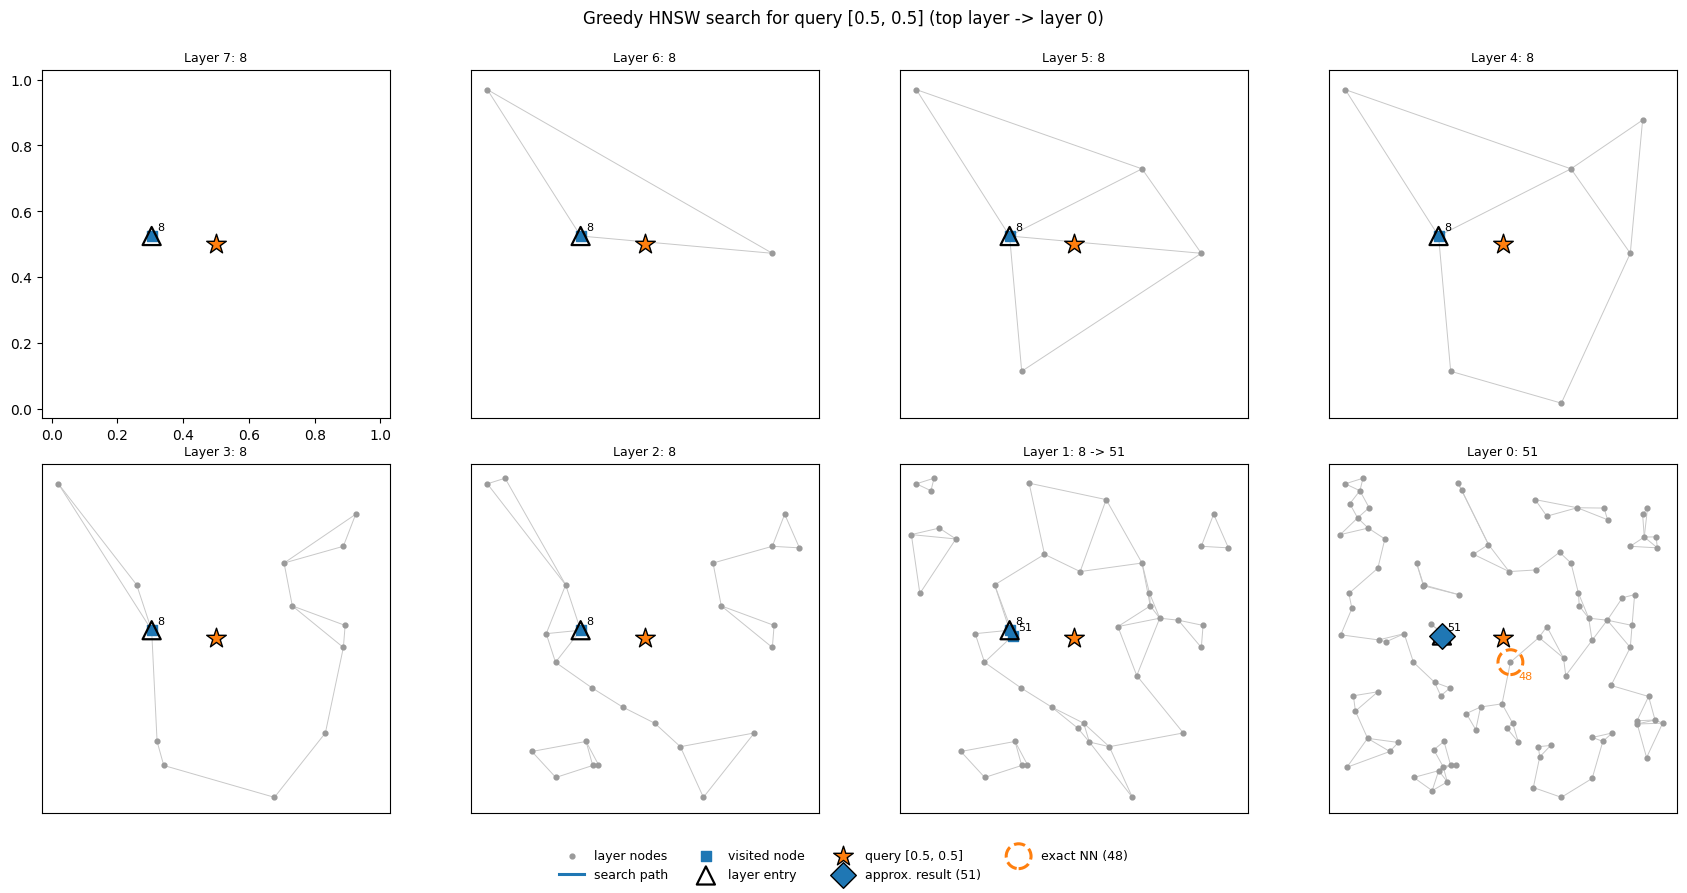

Full top-to-bottom HNSW path


,Layer,Step,Original Row ID,Vector,Distance
0,7,0,8,"[0.3042, 0.5248]",0.197317
1,6,0,8,"[0.3042, 0.5248]",0.197317
2,5,0,8,"[0.3042, 0.5248]",0.197317
3,4,0,8,"[0.3042, 0.5248]",0.197317
4,3,0,8,"[0.3042, 0.5248]",0.197317
5,2,0,8,"[0.3042, 0.5248]",0.197317
6,1,0,8,"[0.3042, 0.5248]",0.197317
7,1,1,51,"[0.3144, 0.5086]",0.185842
8,0,0,51,"[0.3144, 0.5086]",0.185842


Approximate index: 51 | distance: 0.1858
Exact index: 48 | distance: 0.0759
Fixed-query agreement: False

Layer-0 neighbours of the final node 51 (distance to query):
  node 23: 0.1894   (final node 51: 0.1858)
  node 8: 0.1973   (final node 51: 0.1858)
Layer 0 has 9 connected components; final node 51 and exact NN 48 are in the same component: False


In [9]:
# TODO: visualize one example path through the layers, including layer 0.
# Use node IDs, distinct marker shapes, a legend, and a full layer/path text table.

nearest_index, per_layer_paths = search_HNSW(GraphArray, query_vec)
bf_distances, exact_index = nearest_neighbor(vectors, query_vec)

BLUE, ORANGE, GREY = "#1f77b4", "#ff7f0e", "#9a9a9a"
n_panels = len(per_layer_paths)                      # one panel per layer, top -> layer 0
ncols = 4
nrows = int(np.ceil(n_panels / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 4.4 * nrows), squeeze=False)
for ax in axes.flat[n_panels:]:
    ax.axis("off")

for ax, (layer, path) in zip(axes.flat, per_layer_paths):
    G = GraphArray[layer]
    pos = nx.get_node_attributes(G, "pos")
    # all nodes / edges of this layer (neutral grey)
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#c8c8c8", width=0.7)
    xy = np.array(list(pos.values()))
    ax.scatter(xy[:, 0], xy[:, 1], s=12, c=GREY, marker="o", label="layer nodes", zorder=2)
    # search path in this layer (blue line + squares), labelled with original row IDs
    p = np.array([pos[n] for n in path])
    ax.plot(p[:, 0], p[:, 1], "-", color=BLUE, lw=2.2, label="search path", zorder=3)
    ax.scatter(p[:, 0], p[:, 1], s=55, c=BLUE, marker="s", label="visited node", zorder=4)
    ax.scatter(*pos[path[0]], s=170, facecolors="none", edgecolors="k", marker="^", lw=1.6,
               label="layer entry", zorder=5)
    for n in path:
        ax.annotate(str(n), pos[n], xytext=(4, 4), textcoords="offset points", fontsize=8)
    # query (orange star)
    ax.scatter(*query_vec, s=220, c=ORANGE, marker="*", edgecolors="k", label="query [0.5, 0.5]", zorder=6)
    if layer == 0:
        # approximate result (blue diamond) and exact nearest neighbour (dashed orange ring)
        ax.scatter(*pos[nearest_index], s=170, c=BLUE, marker="D", edgecolors="k",
                   label=f"approx. result ({nearest_index})", zorder=7)
        ax.scatter(*pos[exact_index], s=320, facecolors="none", edgecolors=ORANGE, marker="o",
                   lw=2.2, linestyle="--", label=f"exact NN ({exact_index})", zorder=8)
        ax.annotate(str(exact_index), pos[exact_index], xytext=(6, -12), textcoords="offset points",
                    fontsize=8, color=ORANGE)
    ax.set_title(f"Layer {layer}: {' -> '.join(map(str, path))}", fontsize=9)
    ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03); ax.set_aspect("equal")

handles, labels = axes.flat[n_panels - 1].get_legend_handles_labels()   # layer-0 panel has all entries
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Greedy HNSW search for query [0.5, 0.5] (top layer -> layer 0)", y=1.0)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

# Full top-to-bottom path table (every layer, including those where the walk does not move)
rows = []
for layer, path in per_layer_paths:
    graph = GraphArray[layer]
    for step, node in enumerate(path):
        vec = np.asarray(graph.nodes[node]["pos"])
        rows.append({"Layer": layer, "Step": step, "Original Row ID": node,
                     "Vector": np.round(vec, 4).tolist(), "Distance": np.linalg.norm(vec - query_vec)})
path_table = pd.DataFrame(rows)
print("Full top-to-bottom HNSW path")
display(path_table)

print("Approximate index:", nearest_index,
      "| distance:", round(float(np.linalg.norm(GraphArray[0].nodes[nearest_index]["pos"] - query_vec)), 4))
print("Exact index:", exact_index, "| distance:", round(float(bf_distances[exact_index]), 4))
print("Fixed-query agreement:", nearest_index == exact_index)

# Why the walk stopped: neighbours of the final node in layer 0, and connectivity of layer 0
last = per_layer_paths[-1][1][-1]
print(f"\nLayer-0 neighbours of the final node {last} (distance to query):")
for nb in sorted(GraphArray[0].neighbors(last), key=lambda n: bf_distances[n]):
    print(f"  node {nb}: {bf_distances[nb]:.4f}   (final node {last}: {bf_distances[last]:.4f})")
comp = {n: k for k, cc in enumerate(nx.connected_components(GraphArray[0])) for n in cc}
print(f"Layer 0 has {nx.number_connected_components(GraphArray[0])} connected components; "
      f"final node {last} and exact NN {exact_index} are in the same component: {comp[last] == comp[exact_index]}")

#### Calculate and report accuracy of approximate search

After running your evaluation, complete the analysis in this Markdown cell:

- Fixed-query agreement and distances: **TODO**
- Mean search times (1,000 repetitions; include units): **TODO**
- Recall@1 (200 seeded random queries): **TODO**
- Explain any local-minimum errors and the observed timing difference: **TODO**
- Explain construction cost and why M is not a degree bound: **TODO**


#### Calculate and report accuracy of approximate search

*(Results from this notebook: data seed 42, `m_neighbors = 2`, evaluation seed 0. Timings vary slightly between runs.)*

- **Fixed-query agreement and distances:**
  - For the query `[0.5, 0.5]`, greedy HNSW returns **index 51** (`[0.3144, 0.5086]`, distance **0.1858**).
  - Exact search returns **index 48** (`[0.5227, 0.4275]`, distance **0.0759**).
  - The two **do not agree** on this query: the returned point is about 2.4× farther than the true nearest neighbour.
  - Path: the search enters at node **8** in layer 7 and stays there through layers 7 → 2, because no neighbour of 8 is closer to the query in those layers. In layer 1 it moves **8 → 51**. In layer 0, the neighbours of 51, node 23 (0.1894) and node 8 (0.1973), are both farther than 51, so the walk stops at 51.
- **Mean search times (1,000 repetitions; include units):**
  - HNSW greedy search: **113.4 µs per query**.
  - Brute force (vectorized NumPy): **10.7 µs per query**.
  - At this scale brute force is **about 10× faster**.
- **Recall@1 (200 seeded random queries):**
  - **139 / 200 = 0.695.** This is a rate over 200 random queries. It is different from the single fixed query above, which happened to be a miss.
  - Of all 200 queries, **89%** returned a point among the 5 true nearest.
  - On the 61 misses, the returned point is on average **5.0×** farther than the exact nearest neighbour (maximum 81×).
- **Explain any local-minimum errors and the observed timing difference:**
  - *Why it misses:* greedy search stops as soon as no neighbour of the current node is strictly closer to the query. That node is a local minimum of the graph, not necessarily the true nearest point.
  - *Disconnected clusters:* with M = 2 the graph is very sparse. Layer 0 has 129 edges (mean degree 2.58) and splits into **9 disconnected components**. If the descent enters the wrong component, the true nearest neighbour is unreachable.
  - *How often this happens:* it causes **48 of the 61 misses**, including the fixed query: node 51 and node 48 lie in different components of layer 0. The other 13 misses are dead ends inside a component, where every neighbour is farther even though a closer point exists further along the graph.
  - *Why some ratios are very large:* this happens when the query lies almost on top of a point in another component.
  - *How production HNSW avoids this:* it uses larger M, neighbour-selection heuristics and a beam of `ef` candidates. The bonus shows recall rising quickly with M.
  - *Why brute force is faster here:* with only 100 points, one vectorized NumPy call (compiled loop, contiguous memory) costs less than the greedy walk's interpreted Python loop over NetworkX adjacency, with a separate small distance computation for every neighbour checked. HNSW's advantage is asymptotic: about O(log n) hops instead of an O(n) scan. It only appears for large n, in a compiled implementation.
- **Explain construction cost and why M is not a degree bound:**
  - *Construction cost:* every layer computes all-pairs distances, which is O(n_l² · d) for a layer with n_l nodes (plus a sort per node). Layer sizes shrink geometrically (100, 42, 24, 13, 7, 5, 3, 1), so layer 0 dominates and the total is **O(n² d)** time, with O(n·M) edges. Production HNSW instead inserts points one at a time, using the search itself to find neighbours, at about O(n log n).
  - *Why M is not a degree bound:* each node *creates* M undirected links to its M nearest neighbours, but it can also *receive* links from other nodes that chose it. With M = 2 the maximum degree in layer 0 is **5**, and in the bonus it is 8 for M = 4 and 14 for M = 8. M is therefore the number of links a node creates, not a maximum degree; the mean degree lies between M and 2M.



In [10]:
N_EVAL = 200
np.random.seed(0)
eval_queries = np.random.rand(N_EVAL, dimension)
# TODO: compare approximate and exact nearest indices for each query.
# Report recall@1 = number of exact-index matches / N_EVAL, then complete analysis above.
correct = 0
results = []

for i, q in enumerate(eval_queries):

    # Approximate nearest neighbor
    approx_idx, _ = search_HNSW(GraphArray, q)

    # Exact nearest neighbor
    distances, exact_idx = nearest_neighbor(vectors, q)

    match = int(approx_idx == exact_idx)
    correct += match

    results.append({
        "Query": i,
        "Approximate Index": approx_idx,
        "Exact Index": exact_idx,
        "Match": bool(match)
    })

recall_at_1 = correct / N_EVAL

print(f"Correct matches: {correct}/{N_EVAL}")
print(f"Recall@1: {recall_at_1:.4f}")
print(f"Recall@1 (%): {recall_at_1 * 100:.2f}%")

eval_table = pd.DataFrame(results)
display(eval_table.head(10))
eval_table["Approx Distance"] = [np.linalg.norm(vectors[a] - q) for a, q in zip(eval_table["Approximate Index"], eval_queries)]
eval_table["Exact Distance"] = [np.linalg.norm(vectors[e] - q) for e, q in zip(eval_table["Exact Index"], eval_queries)]
eval_table["Rank of returned point"] = [int(np.sum(np.linalg.norm(vectors - q, axis=1) < d)) + 1
                                        for q, d in zip(eval_queries, eval_table["Approx Distance"])]
misses = eval_table[~eval_table["Match"]]
comp = {n: k for k, cc in enumerate(nx.connected_components(GraphArray[0])) for n in cc}
cross = sum(comp[a] != comp[e] for a, e in zip(misses["Approximate Index"], misses["Exact Index"]))
ratio = misses["Approx Distance"] / misses["Exact Distance"]

print(f"\nMisses: {len(misses)}/{N_EVAL}")
print(f"Returned point is within the true 5 nearest: {(eval_table['Rank of returned point'] <= 5).mean():.3f} of queries")
print(f"Distance ratio approx/exact on misses: mean {ratio.mean():.2f}, max {ratio.max():.2f}")
print(f"Layer 0: {GraphArray[0].number_of_edges()} edges, {nx.number_connected_components(GraphArray[0])} connected "
      f"components, max degree {max(d for _, d in GraphArray[0].degree())} (M = {m_neighbors})")
print(f"Misses whose exact NN is in a different layer-0 component than the returned node: {cross}/{len(misses)}")


Correct matches: 139/200
Recall@1: 0.6950
Recall@1 (%): 69.50%


,Query,Approximate Index,Exact Index,Match
0,0,68,68,True
1,1,81,81,True
2,2,53,80,False
3,3,0,0,True
4,4,44,67,False
5,5,93,93,True
6,6,27,27,True
7,7,49,49,True
8,8,36,36,True
9,9,99,60,False



Misses: 61/200
Returned point is within the true 5 nearest: 0.890 of queries
Distance ratio approx/exact on misses: mean 5.01, max 81.06
Layer 0: 129 edges, 9 connected components, max degree 5 (M = 2)
Misses whose exact NN is in a different layer-0 component than the returned node: 48/61


## Problem 4 Bonus (optional)

- **(+3 points)** Compare `m_neighbors` **2, 4, 8** using the existing 200-query
  evaluation: report measured build time, search time, recall, and graph size.
- **(+2 points)** Test on real embeddings (e.g. GloVe trained on Wikipedia/Gigaword)
  and report results with the dataset, subset size, dimension, and query source.
  Downloading embeddings is **opt-in**, not part of the required notebook run.
  Failed/skipped downloads are not completed experiments.


Brute force on the same queries: see the timing cell above


build time (ms)         search time (µs/query)         recall@1         \
             mean     std                   mean     std     mean    std   
M                                                                          
2         168.671  71.994                338.305  35.613    0.739  0.025   
4         101.908   3.126                318.256  13.336    0.899  0.007   
8          97.474   2.231                413.083  16.517    0.988  0.011   

  layers        total edges         layer-0 edges      layer-0 max degree  \
    mean    std        mean     std          mean  std               mean   
M                                                                           
2    7.2  0.837       262.0  14.405         129.0  0.0                5.0   
4    3.8  0.447       330.4  14.328         251.0  0.0                8.0   
8    2.8  0.447       523.0  17.349         464.0  0.0               14.0   

       layer-0 components       
   std               mean  std  
M                               
2  0.0                9.0  0.0  
4  0.0                1.0  0.0  
8  0.0                1.0  0.0

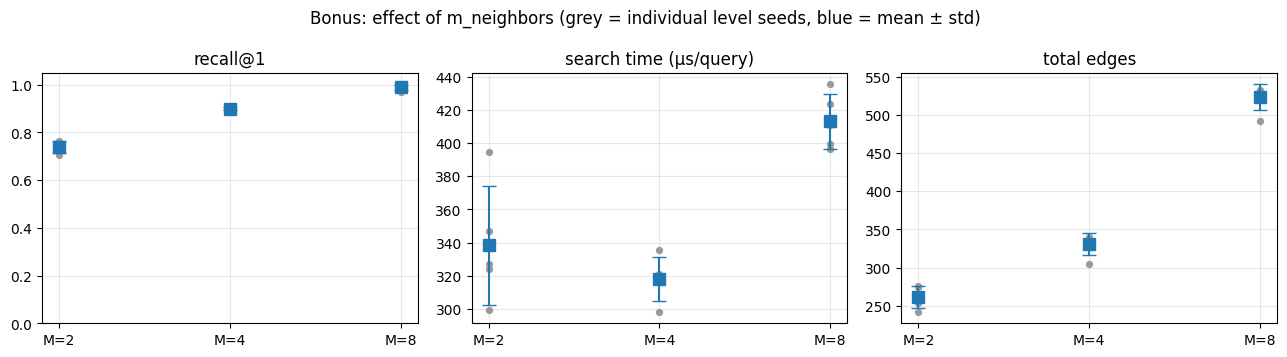

In [11]:
# Optional bonuses only. Complete and analyze these experiments if attempting them.
# (+3): compare M = 2, 4, 8 on the same 100 vectors and the same 200 evaluation queries.
# Level assignment is random, so each M is built with 5 level seeds; we report mean +/- std.
M_VALUES, LEVEL_SEEDS = (2, 4, 8), range(5)
exact_ids = np.array([nearest_neighbor(vectors, q)[1] for q in eval_queries])

bonus_rows = []
for M in M_VALUES:
    for s in LEVEL_SEEDS:
        np.random.seed(100 + s)                                   # seed only the level assignment
        t0 = time.perf_counter(); layers = construct_HNSW(vectors, M); t_build = time.perf_counter() - t0
        t0 = time.perf_counter(); ids = np.array([search_HNSW(layers, q)[0] for q in eval_queries])
        t_search = (time.perf_counter() - t0) / N_EVAL
        bonus_rows.append({"M": M, "level seed": 100 + s, "build time (ms)": t_build * 1e3,
                           "search time (µs/query)": t_search * 1e6, "recall@1": np.mean(ids == exact_ids),
                           "layers": len(layers), "total edges": sum(G.number_of_edges() for G in layers),
                           "layer-0 edges": layers[0].number_of_edges(),
                           "layer-0 max degree": max(d for _, d in layers[0].degree()),
                           "layer-0 components": nx.number_connected_components(layers[0])})
bonus_df = pd.DataFrame(bonus_rows)
summary = bonus_df.drop(columns="level seed").groupby("M").agg(["mean", "std"]).round(3)
print("Brute force on the same queries: see the timing cell above")
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["recall@1", "search time (µs/query)", "total edges"]):
    for k, M in enumerate(M_VALUES):
        vals = bonus_df.loc[bonus_df["M"] == M, col]
        ax.scatter(np.full(len(vals), k), vals, color="#9a9a9a", s=18, zorder=2)
        ax.errorbar(k, vals.mean(), yerr=vals.std(), fmt="s", color="#1f77b4", ms=8, capsize=5, zorder=3)
    ax.set_xticks(range(len(M_VALUES))); ax.set_xticklabels([f"M={M}" for M in M_VALUES])
    ax.set_title(col); ax.grid(alpha=0.3)
axes[0].set_ylim(0, 1.05)
fig.suptitle("Bonus: effect of m_neighbors (grey = individual level seeds, blue = mean ± std)")
plt.tight_layout(); plt.show()

RUN_REAL_EMBEDDINGS = False  # Set True only if opting into an external download.
if RUN_REAL_EMBEDDINGS:
    # TODO (+2): load real embeddings and report dataset/query provenance and results.
    raise NotImplementedError("Optional real-embedding experiment")

\#### Bonus results and analysis

**(+3) Effect of `m_neighbors`.** Same 100 vectors and same 200 evaluation queries; each M is built with 5 level seeds (100–104); values are means.

| M | recall@1 (mean ± std) | layers | total edges | layer-0 edges | layer-0 max degree | layer-0 components |
|---|---|---|---|---|---|---|
| 2 | 0.739 ± 0.025 | 7.2 | 262 | 129 | 5 | 9 |
| 4 | 0.899 ± 0.007 | 3.8 | 330 | 251 | 8 | 1 |
| 8 | 0.988 ± 0.011 | 2.8 | 523 | 464 | 14 | 1 |

*(Build and search times are in the table above. They grow with M, and brute force remains faster at n = 100.)*

- **Recall rises sharply with M** (0.74 → 0.90 → 0.99). The main reason is connectivity: with M = 2, layer 0 splits into 9 disconnected components, while with M ≥ 4 it is a single connected graph. Greedy search can then always reach the true nearest neighbour's region. More neighbours per node also make dead ends rarer.
- **The costs grow with M.** Every step checks more neighbours, so search time increases. The graph also grows (262 → 523 edges), so memory use and construction work go up.
- **M also changes the hierarchy.** The level formula uses `log(max(M, 2))`, so a larger M produces **fewer layers** (7.2 → 2.8) and a flatter hierarchy.
- **The degree grows faster than M** (maximum 5, 8 and 14), which again shows that M is not a degree bound.
- M trades memory and search time for recall, the same knob that production HNSW exposes.
